# 14 · Set 5d part 1: is there hidden structure that separates easy questions from hard ones? (CPU, about 10 minutes)

Looks for structure in the finished Set 4 results, **without generating any new model answers**. Several ways of looking are scored on
one scoreboard so they can be compared.

| Spaces (what is looked at) | Strategies (how structure is read) | Targets (what "easy" means) |
|---|---|---|
| question facts | linear probe | the small pipeline is right |
| question text, topics, embedding | first 2 principal components (PCA) | the cheap answer is no worse than the big one |
| question–passage similarity | nearest neighbours (the neighbourhoods t-SNE draws) | the best setup is right |
| metadata of the small pipeline and of a cheap run | k-means clusters | the small retriever finds both passages |
| agreement between two small answerers | a small decision tree; boosted trees | the question is easy for most setups |
| all signals available after the cheap run | association rules | |

**Every score is on held-out questions**, shown next to the score the same method gets when the labels are shuffled. PCA and t-SNE maps
are drawn, but a picture is not the evidence; the held-out number is. Association rules are found on the dev half and checked on the test half.

Output: `runs/Set_2__question-reading-routers/<timestamp>_cpu_structure/` with `results/summary.md`, `results/set5d_structure.xlsx`, `results/charts/`
(9 charts), `results/association_rules.jsonl`, `results/tree_rules.txt`, `results/topics.jsonl`, `results/clusters.jsonl`.

**No GPU needed: Runtime → Change runtime type → CPU.**

In [1]:
# ==== settings ====
PROJECT_DIR = "/content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching"
EXPERIMENT  = "Set_2__question-reading-routers"
SWEEP_EXPERIMENT = "Set_1__3-modality-size"     # the finished Set 4 sweep these policies are computed from
SWEEP_RUN_OVERRIDE = None             # or paste a sweep run folder; None = the latest complete one
REPEATS = 3                           # repeats of the 5-fold cross-validation
PERMUTATIONS = 20                     # label shuffles per combination for the control
USE_EMBEDDING = True                  # also use a sentence-embedding model for questions and passages (downloads ~90 MB once)
NEW_RUN = True                        # each run of this notebook gets its own folder (it only takes minutes)

In [2]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
import glob, json, os, shutil, subprocess, sys, time
from datetime import datetime
from zoneinfo import ZoneInfo
T_START = time.time()
SESSION = datetime.now(ZoneInfo("Asia/Singapore")).strftime("%Y%m%d-%H%M%S")
if SWEEP_RUN_OVERRIDE:
    SWEEP_RUN = SWEEP_RUN_OVERRIDE
else:
    done = [d for d in sorted(glob.glob(f"{PROJECT_DIR}/runs/{SWEEP_EXPERIMENT}/*")) if "_dryrun" not in d
            and os.path.exists(f"{d}/sweep_status.json") and json.load(open(f"{d}/sweep_status.json")).get("complete")
            and os.path.exists(f"{d}/results/per_question.jsonl")]
    assert done, f"No complete sweep found in runs/{SWEEP_EXPERIMENT} - finish notebook 11 first."
    SWEEP_RUN = done[-1]
DATA_DIR = json.load(open(f"{SWEEP_RUN}/config.json"))["data_dir"]
prev = sorted(glob.glob(f"{PROJECT_DIR}/runs/{EXPERIMENT}/*_cpu_structure"))
RUN_DIR = prev[-1] if (prev and not NEW_RUN) else f"{PROJECT_DIR}/runs/{EXPERIMENT}/{SESSION}_cpu_structure"
SESSION_DIR = f"{RUN_DIR}/sessions/{SESSION}_structure"
for d in (f"{RUN_DIR}/code", f"{RUN_DIR}/logs", SESSION_DIR):
    os.makedirs(d, exist_ok=True)
CODE_DIR = "/content/set5code"
os.makedirs(CODE_DIR, exist_ok=True)
for f in ("ssw.py", "sweep.py", "routers.py", "structure.py"):
    shutil.copy(f"{PROJECT_DIR}/code/{f}", f"{CODE_DIR}/{f}")
    shutil.copy(f"{PROJECT_DIR}/code/{f}", f"{RUN_DIR}/code/{f}")       # keep the exact code with the results
json.dump({"experiment": EXPERIMENT, "set": "5d part 1", "sweep_run": SWEEP_RUN, "data_dir": DATA_DIR, "repeats": REPEATS, "permutations": PERMUTATIONS,
           "use_embedding": USE_EMBEDDING, "started": SESSION}, open(f"{RUN_DIR}/config.json", "w"), indent=1)
print("Set 4 sweep used:", SWEEP_RUN)
print("Run folder:", RUN_DIR)

Set 4 sweep used: /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/Set_1__3-modality-size/20261004-165402_A100
Run folder: /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/Set_2__question-reading-routers/20261006-181713_cpu_structure


In [4]:
# the embedding model is optional: without it the TF-IDF text features still run
if USE_EMBEDDING:
    try:
        import sentence_transformers
    except ImportError:
        print("installing sentence-transformers ...")
        !pip install -q sentence-transformers

### Run every strategy (about 10 minutes)

In [5]:
cmd = [sys.executable, "-u", f"{CODE_DIR}/structure.py", "offline", "--sweep_run", SWEEP_RUN, "--data_dir", DATA_DIR,
       "--run_dir", RUN_DIR, "--repeats", str(REPEATS), "--permutations", str(PERMUTATIONS)] + ([] if USE_EMBEDDING else ["--no_embedding"])
with open(f"{RUN_DIR}/logs/structure.log", "a") as log, open(f"{SESSION_DIR}/structure.log", "a") as slog:
    p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    for line in p.stdout:
        log.write(line); slog.write(line)
        print(line, end="")
    p.wait()
assert p.returncode == 0, f"failed - see {RUN_DIR}/logs/structure.log"

[10:17:51] reading /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/Set_1__3-modality-size/20261004-165402_A100/results/per_question.jsonl ...
[10:17:58] 200 questions (100 dev, 100 test), 648 setups

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 5125.81it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 4505.49it/s]
[10:23:24] embedding: all-MiniLM-L6-v2 (22.7M parameters)
[10:23:24] spaces: {'question facts': 13, 'question text (TF-IDF)': 16, 'question topics (NMF, 6 topics)': 6, 'question-passage similarity (TF-IDF)': 9, 'question embedding': 16, 'question-passage similarity (embedding)': 8, 'metadata of the small pipeline (Qwen 3B - Llama 3B)': 12, 'metadata of the cheap run (Qwen 7B - Llama 8B)': 12, 'cross-model agreement (Llama 3B vs Llama 8B answers)': 4, 'all signals available after the cheap run': 34}
[10:24:28]   scoreboard: 35/350
[10:25:38]   scoreboard: 70/350
[10:26:34]   scoreboard: 105/350
[10:27:44]   scoreboard: 140/350


### Results

# Set 5d part 1 - looking for hidden structure in the Set 4 results

Sweep used: `20261004-165402_A100`. 200 questions. No new model answers were generated. Embedding model: all-MiniLM-L6-v2 (22.7M parameters).
Every separation score is on held-out questions (5-fold cross-validation x3). 0.5 = useless, 1.0 = perfect. 'Beats shuffled labels' = higher than the 95th percentile of the same method run on 20 shuffles of the labels.
108 of 335 combinations beat shuffled labels; by chance alone about 17 would.

## 1. What 'easy' means here

| Target | Share of the 200 questions |
|---|---|
| small pipeline is right | 36.5% |
| cheap answer is no worse than the big one | 85.5% |
| the best setup is right | 65.0% |
| small retriever finds both passages | 67.5% |
| easy for most setups (above the median) | 50.0% |

## 2. Top 25 combinations on the scoreboard

| What is looked at | How structure is read | What 'easy' means | Separation on held-out questions (0.5 = useless) | Same method with shuffled labels: 95th percentile | Beats shuffled labels | Cost of having this signal |
|---|---|---|---|---|---|---|
| cross-model agreement (Llama 3B vs Llama 8B answers) | first 2 principal components (PCA) | cheap answer is no worse than the big one | 0.84 | 0.60 | True | needs both small answerers on the shared shortlist: about 3.9x |
| cross-model agreement (Llama 3B vs Llama 8B answers) | linear probe | cheap answer is no worse than the big one | 0.84 | 0.63 | True | needs both small answerers on the shared shortlist: about 3.9x |
| cross-model agreement (Llama 3B vs Llama 8B answers) | nearest neighbours (t-SNE-style neighbourhoods) | cheap answer is no worse than the big one | 0.82 | 0.60 | True | needs both small answerers on the shared shortlist: about 3.9x |
| cross-model agreement (Llama 3B vs Llama 8B answers) | boosted trees | cheap answer is no worse than the big one | 0.81 | 0.60 | True | needs both small answerers on the shared shortlist: about 3.9x |
| cross-model agreement (Llama 3B vs Llama 8B answers) | decision tree (depth 3) | cheap answer is no worse than the big one | 0.81 | 0.64 | True | needs both small answerers on the shared shortlist: about 3.9x |
| cross-model agreement (Llama 3B vs Llama 8B answers) | k-means clusters (6) | cheap answer is no worse than the big one | 0.80 | 0.54 | True | needs both small answerers on the shared shortlist: about 3.9x |
| cross-model agreement (Llama 3B vs Llama 8B answers) | linear probe | easy for most setups (above the median) | 0.77 | 0.56 | True | needs both small answerers on the shared shortlist: about 3.9x |
| cross-model agreement (Llama 3B vs Llama 8B answers) | association rules | cheap answer is no worse than the big one | 0.77 | 0.58 | True | needs both small answerers on the shared shortlist: about 3.9x |
| metadata of the cheap run (Qwen 7B - Llama 8B) | nearest neighbours (t-SNE-style neighbourhoods) | cheap answer is no worse than the big one | 0.77 | 0.59 | True | needs the cheap run to have run: about 3.5x |
| cross-model agreement (Llama 3B vs Llama 8B answers) | nearest neighbours (t-SNE-style neighbourhoods) | easy for most setups (above the median) | 0.77 | 0.55 | True | needs both small answerers on the shared shortlist: about 3.9x |
| metadata of the cheap run (Qwen 7B - Llama 8B) | first 2 principal components (PCA) | cheap answer is no worse than the big one | 0.76 | 0.56 | True | needs the cheap run to have run: about 3.5x |
| cross-model agreement (Llama 3B vs Llama 8B answers) | first 2 principal components (PCA) | easy for most setups (above the median) | 0.76 | 0.55 | True | needs both small answerers on the shared shortlist: about 3.9x |
| cross-model agreement (Llama 3B vs Llama 8B answers) | association rules | easy for most setups (above the median) | 0.76 | 0.55 | True | needs both small answerers on the shared shortlist: about 3.9x |
| all signals available after the cheap run | boosted trees | cheap answer is no worse than the big one | 0.75 | 0.65 | True | about 3.5x |
| metadata of the cheap run (Qwen 7B - Llama 8B) | linear probe | cheap answer is no worse than the big one | 0.75 | 0.61 | True | needs the cheap run to have run: about 3.5x |
| all signals available after the cheap run | linear probe | easy for most setups (above the median) | 0.75 | 0.58 | True | about 3.5x |
| cross-model agreement (Llama 3B vs Llama 8B answers) | decision tree (depth 3) | easy for most setups (above the median) | 0.75 | 0.55 | True | needs both small answerers on the shared shortlist: about 3.9x |
| cross-model agreement (Llama 3B vs Llama 8B answers) | boosted trees | easy for most setups (above the median) | 0.75 | 0.55 | True | needs both small answerers on the shared shortlist: about 3.9x |
| cross-model agreement (Llama 3B vs Llama 8B answers) | k-means clusters (6) | easy for most setups (above the median) | 0.74 | 0.56 | True | needs both small answerers on the shared shortlist: about 3.9x |
| metadata of the cheap run (Qwen 7B - Llama 8B) | decision tree (depth 3) | cheap answer is no worse than the big one | 0.73 | 0.60 | True | needs the cheap run to have run: about 3.5x |
| metadata of the cheap run (Qwen 7B - Llama 8B) | linear probe | easy for most setups (above the median) | 0.73 | 0.57 | True | needs the cheap run to have run: about 3.5x |
| metadata of the cheap run (Qwen 7B - Llama 8B) | boosted trees | cheap answer is no worse than the big one | 0.73 | 0.57 | True | needs the cheap run to have run: about 3.5x |
| metadata of the cheap run (Qwen 7B - Llama 8B) | first 2 principal components (PCA) | easy for most setups (above the median) | 0.73 | 0.56 | True | needs the cheap run to have run: about 3.5x |
| metadata of the cheap run (Qwen 7B - Llama 8B) | k-means clusters (6) | cheap answer is no worse than the big one | 0.73 | 0.59 | True | needs the cheap run to have run: about 3.5x |
| metadata of the cheap run (Qwen 7B - Llama 8B) | boosted trees | easy for most setups (above the median) | 0.72 | 0.58 | True | needs the cheap run to have run: about 3.5x |

## 3. Best way of reading each space, for the routing target ('cheap answer is no worse than the big one')

| What is looked at | How structure is read | Separation on held-out questions (0.5 = useless) | Same method with shuffled labels: 95th percentile | Beats shuffled labels | Cost of having this signal |
|---|---|---|---|---|---|
| cross-model agreement (Llama 3B vs Llama 8B answers) | first 2 principal components (PCA) | 0.84 | 0.60 | True | needs both small answerers on the shared shortlist: about 3.9x |
| metadata of the cheap run (Qwen 7B - Llama 8B) | nearest neighbours (t-SNE-style neighbourhoods) | 0.77 | 0.59 | True | needs the cheap run to have run: about 3.5x |
| all signals available after the cheap run | boosted trees | 0.75 | 0.65 | True | about 3.5x |
| question text (TF-IDF) | decision tree (depth 3) | 0.69 | 0.57 | True | free |
| question topics (NMF, 6 topics) | boosted trees | 0.57 | 0.59 | False | free |
| question-passage similarity (embedding) | first 2 principal components (PCA) | 0.56 | 0.61 | False | 22.7M-parameter model reads the 20 passages: about 0.005x |
| metadata of the small pipeline (Qwen 3B - Llama 3B) | first 2 principal components (PCA) | 0.55 | 0.59 | False | needs the small pipeline to have run: about 1.3x |
| question embedding | nearest neighbours (t-SNE-style neighbourhoods) | 0.50 | 0.59 | False | 22.7M-parameter model reads the question: under 0.001x |
| question facts | boosted trees | 0.49 | 0.60 | False | free |
| question-passage similarity (TF-IDF) | association rules | 0.43 | 0.59 | False | free |

## 4. Which way of reading structure works best? (mean over all spaces and targets)

| How structure is read | Separation on held-out questions (0.5 = useless) | Share of its combinations that beat shuffled labels |
|---|---|---|
| linear probe | 0.56 | 34.0% |
| first 2 principal components (PCA) | 0.54 | 34.0% |
| nearest neighbours (t-SNE-style neighbourhoods) | 0.55 | 34.0% |
| k-means clusters (6) | 0.52 | 20.0% |
| decision tree (depth 3) | 0.53 | 30.0% |
| boosted trees | 0.56 | 34.0% |
| association rules | 0.57 | 42.9% |

## 5. What the best signal of each space would buy as a gate (35% of questions escalated, reference pair)

| Gate | Accuracy | Compute (x cheapest) | Share escalated | Separation |
|---|---|---|---|---|
| always the cheap answerer | 54.5% | 3.5x | 0.0% | - |
| always the big answerer (fixed) | 64.0% | 5.8x | 100.0% | - |
| escalate a random 35% | 57.8% | 4.9x | 35.0% | 0.50 |
| cross-model agreement (Llama 3B vs Llama 8B answers) | first 2 principal components (PCA) | 62.0% | 5.0x | 35.0% | 0.84 |
| metadata of the cheap run (Qwen 7B - Llama 8B) | nearest neighbours (t-SNE-style neighbourhoods) | 65.0% | 5.3x | 41.0% | 0.77 |
| all signals available after the cheap run | boosted trees | 61.5% | 5.0x | 35.0% | 0.75 |
| question text (TF-IDF) | decision tree (depth 3) | 60.5% | 4.9x | 35.0% | 0.69 |
| question topics (NMF, 6 topics) | boosted trees | 61.5% | 4.9x | 35.0% | 0.57 |
| question-passage similarity (embedding) | first 2 principal components (PCA) | 58.0% | 4.8x | 35.0% | 0.56 |
| metadata of the small pipeline (Qwen 3B - Llama 3B) | first 2 principal components (PCA) | 59.5% | 5.0x | 35.0% | 0.55 |
| question embedding | nearest neighbours (t-SNE-style neighbourhoods) | 58.5% | 5.1x | 38.5% | 0.50 |
| question facts | boosted trees | 57.5% | 4.9x | 35.0% | 0.49 |
| question-passage similarity (TF-IDF) | association rules | 58.5% | 4.9x | 35.0% | 0.43 |

## 6. Topics in the question text

| Topic | Top words | Questions | Share where: small pipeline is right | Share where: cheap answer is no worse than the big one | Share where: the best setup is right |
|---|---|---|---|---|---|
| 1 | born, castle, author, composer, singer, home, 2014 | 19 | 36.8% | 63.2% | 73.7% |
| 2 | new, new york, york, located, county, state, york state | 23 | 17.4% | 91.3% | 65.2% |
| 3 | did, star, university, university did, singer, band, group | 38 | 39.5% | 92.1% | 52.6% |
| 4 | american, actor, film, common, does, starred, year | 64 | 40.6% | 85.9% | 65.6% |
| 5 | country, includes, mosque, canada, served, director, park | 17 | 29.4% | 82.4% | 76.5% |
| 6 | city, based, population, population city, 2010, located, mountain | 39 | 41.0% | 87.2% | 66.7% |

## 7. Association rules: found on dev, checked on test

A rule 'holds on test' if it still has lift above 1.1 on at least 5 test questions. The control row shows how many rules hold when they were mined from shuffled labels, that is, by chance.

| Target | Mined on | Rules kept (strongest on dev) | Rules that hold on test | Share that hold on test |
|---|---|---|---|---|
| cheap answer is no worse than the big one | real labels | 15 | 8 | 53.3% |
| cheap answer is no worse than the big one | shuffled labels (control) | 15 | 7 | 46.7% |
| small pipeline is right | real labels | 15 | 9 | 60.0% |
| small pipeline is right | shuffled labels (control) | 15 | 6 | 40.0% |
| the best setup is right | real labels | 15 | 8 | 53.3% |
| the best setup is right | shuffled labels (control) | 15 | 6 | 40.0% |

### The strongest rules for 'cheap answer is no worse than the big one'

| IF | THEN | dev questions matching | dev confidence | dev confidence, m-smoothed (m = 5) | dev lift | test questions matching | test confidence | test lift | holds on test (lift > 1.1, at least 5 questions) |
|---|---|---|---|---|---|---|---|---|---|
| capitalised words is low (<= 3) AND agreement of the 5 answers [cheap run] is low (<= 0.6) | NOT (cheap answer is no worse than the big one) | 23 | 34.8% | 30.7% | 2.90 | 21 | 28.6% | 1.68 | True |
| characters is high (> 101) AND passages sharing a name with the question is low (<= 8) | NOT (cheap answer is no worse than the big one) | 8 | 50.0% | 35.4% | 4.17 | 9 | 11.1% | 0.65 | False |
| agreement of the 5 answers [cheap run] is low (<= 0.6) AND answer output tokens [cheap run] is high (> 1.01e+03) | NOT (cheap answer is no worse than the big one) | 20 | 35.0% | 30.4% | 2.92 | 20 | 30.0% | 1.76 | True |
| words is high (> 18) AND capitalised words is low (<= 3) | NOT (cheap answer is no worse than the big one) | 12 | 41.7% | 32.9% | 3.47 | 10 | 10.0% | 0.59 | False |
| capitalised words is low (<= 3) AND characters is high (> 101) | NOT (cheap answer is no worse than the big one) | 12 | 41.7% | 32.9% | 3.47 | 9 | 11.1% | 0.65 | False |
| most similar passage (TF-IDF) is low (<= 0.338) AND passages sharing a name with the question is low (<= 8) | NOT (cheap answer is no worse than the big one) | 12 | 41.7% | 32.9% | 3.47 | 13 | 15.4% | 0.90 | False |
| passages close to the best one (TF-IDF) is low (<= 2) AND agreement of the 5 answers [cheap run] is low (<= 0.6) | NOT (cheap answer is no worse than the big one) | 12 | 41.7% | 32.9% | 3.47 | 16 | 31.2% | 1.84 | True |
| most similar passage (TF-IDF) is low (<= 0.338) AND agreement of the 5 answers [cheap run] is low (<= 0.6) | NOT (cheap answer is no worse than the big one) | 16 | 37.5% | 31.4% | 3.12 | 13 | 23.1% | 1.36 | True |
| agreement of the 5 answers [cheap run] is low (<= 0.6) AND passages in the shortlist [cheap run] is low (<= 2) | NOT (cheap answer is no worse than the big one) | 25 | 32.0% | 28.7% | 2.67 | 25 | 32.0% | 1.88 | True |
| agreement of the 5 answers [cheap run] is low (<= 0.6) | NOT (cheap answer is no worse than the big one) | 35 | 28.6% | 26.5% | 2.38 | 37 | 32.4% | 1.91 | True |
| words is high (> 18) AND passages sharing a name with the question is low (<= 8) | NOT (cheap answer is no worse than the big one) | 9 | 44.4% | 32.9% | 3.70 | 11 | 9.1% | 0.53 | False |
| capitalised words is low (<= 3) AND most similar passage (TF-IDF) is low (<= 0.338) | NOT (cheap answer is no worse than the big one) | 17 | 35.3% | 30.0% | 2.94 | 17 | 17.6% | 1.04 | False |

## 8. Small decision trees (readable rules), learned on dev and scored on test

| What is looked at | Predicting | Test separation | Test accuracy | Test accuracy of always guessing the majority |
|---|---|---|---|---|
| all signals available after the cheap run | cheap answer is no worse than the big one | 0.66 | 79.0% | 83.0% |
| all signals available after the cheap run | small pipeline is right | 0.38 | 54.0% | 63.0% |
| question facts | cheap answer is no worse than the big one | 0.41 | 83.0% | 83.0% |
| question facts | small pipeline is right | 0.53 | 58.0% | 63.0% |
| question-passage similarity (TF-IDF) | cheap answer is no worse than the big one | 0.52 | 83.0% | 83.0% |
| question-passage similarity (TF-IDF) | small pipeline is right | 0.50 | 55.0% | 63.0% |

The trees themselves are in `results/tree_rules.txt`.

## 9. Which single signals matter (for 'cheap answer is no worse than the big one')

| Signal | Drop in held-out separation when this signal is scrambled |
|---|---|
| agreement of the 5 answers [cheap run] | 0.13 |
| words in the answer [cheap run] | 0.03 |
| answer token probability [cheap run] | 0.01 |
| answer output tokens [cheap run] | 0.01 |
| asks 'who' | 0.01 |
| entropy of similarity (TF-IDF) | 0.01 |
| retrieval token probability [cheap run] | 0.00 |
| comparison | 0.00 |
| passages in the shortlist [cheap run] | 0.00 |
| agreement of the 3 retrieval tries [cheap run] | 0.00 |

Charts: `results/charts/` (9). Excel: `results/set5d_structure.xlsx`. Clusters: `results/clusters.jsonl`.


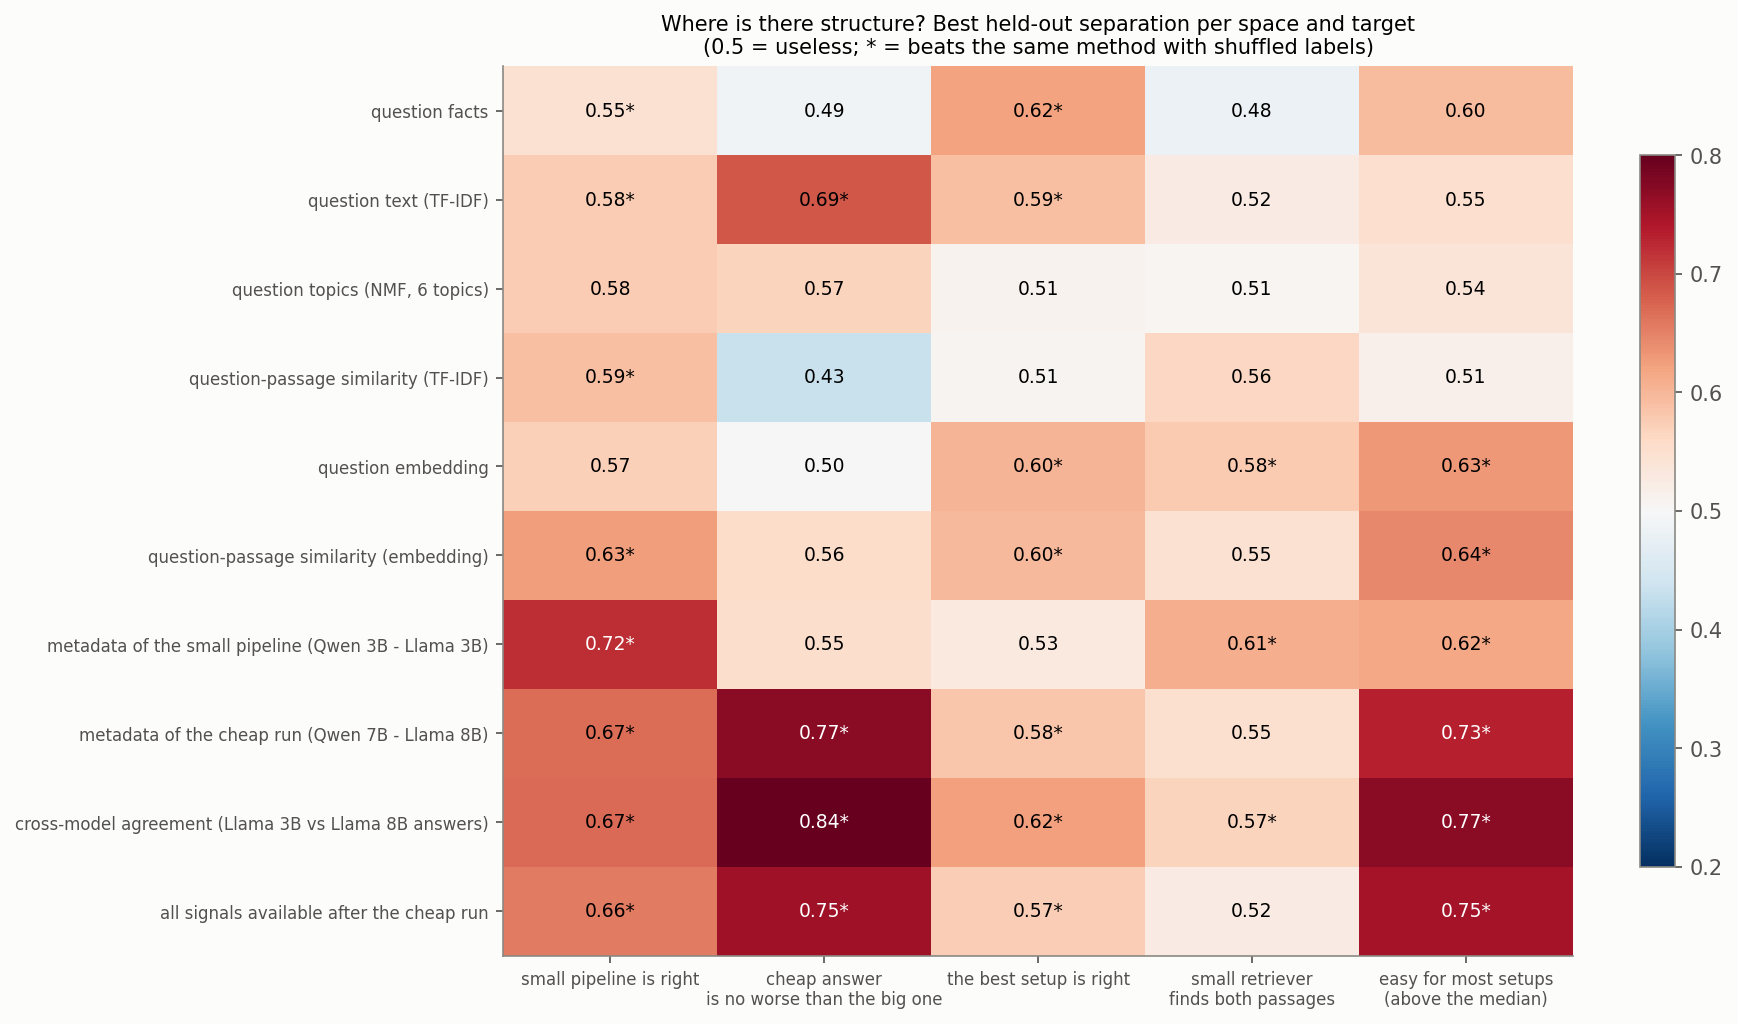

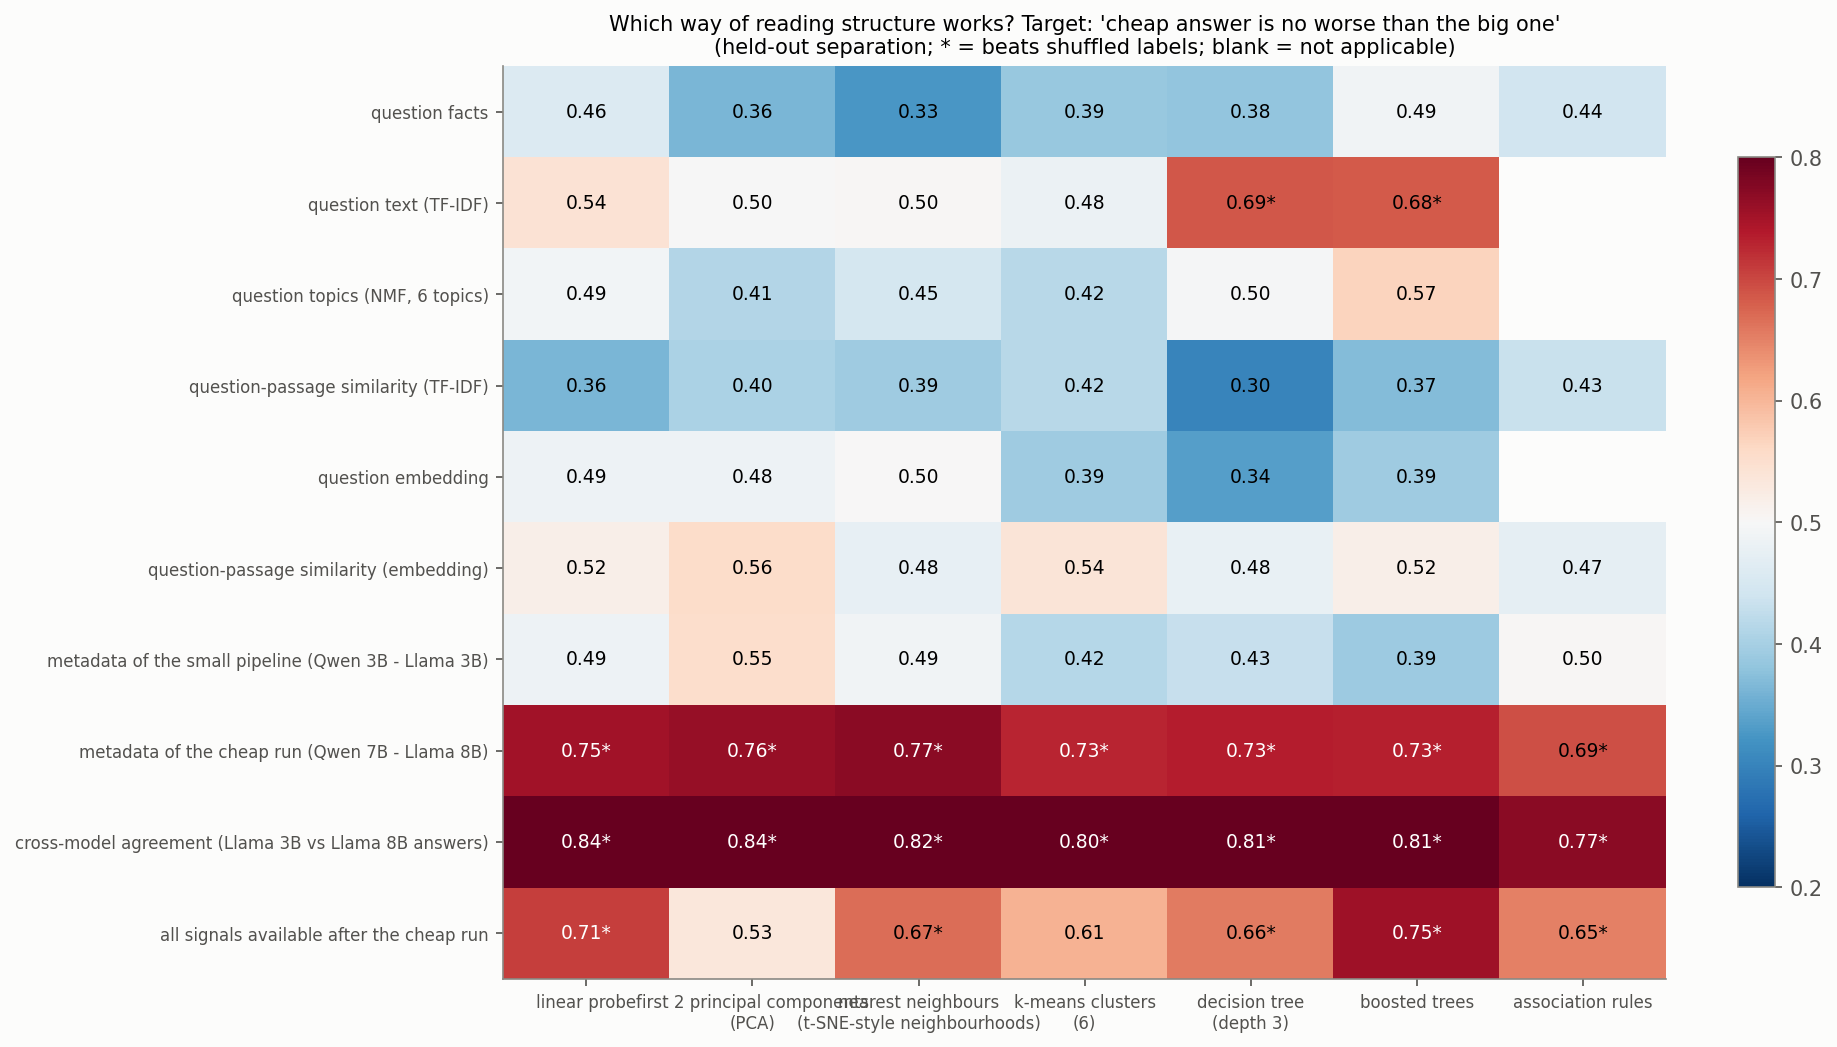

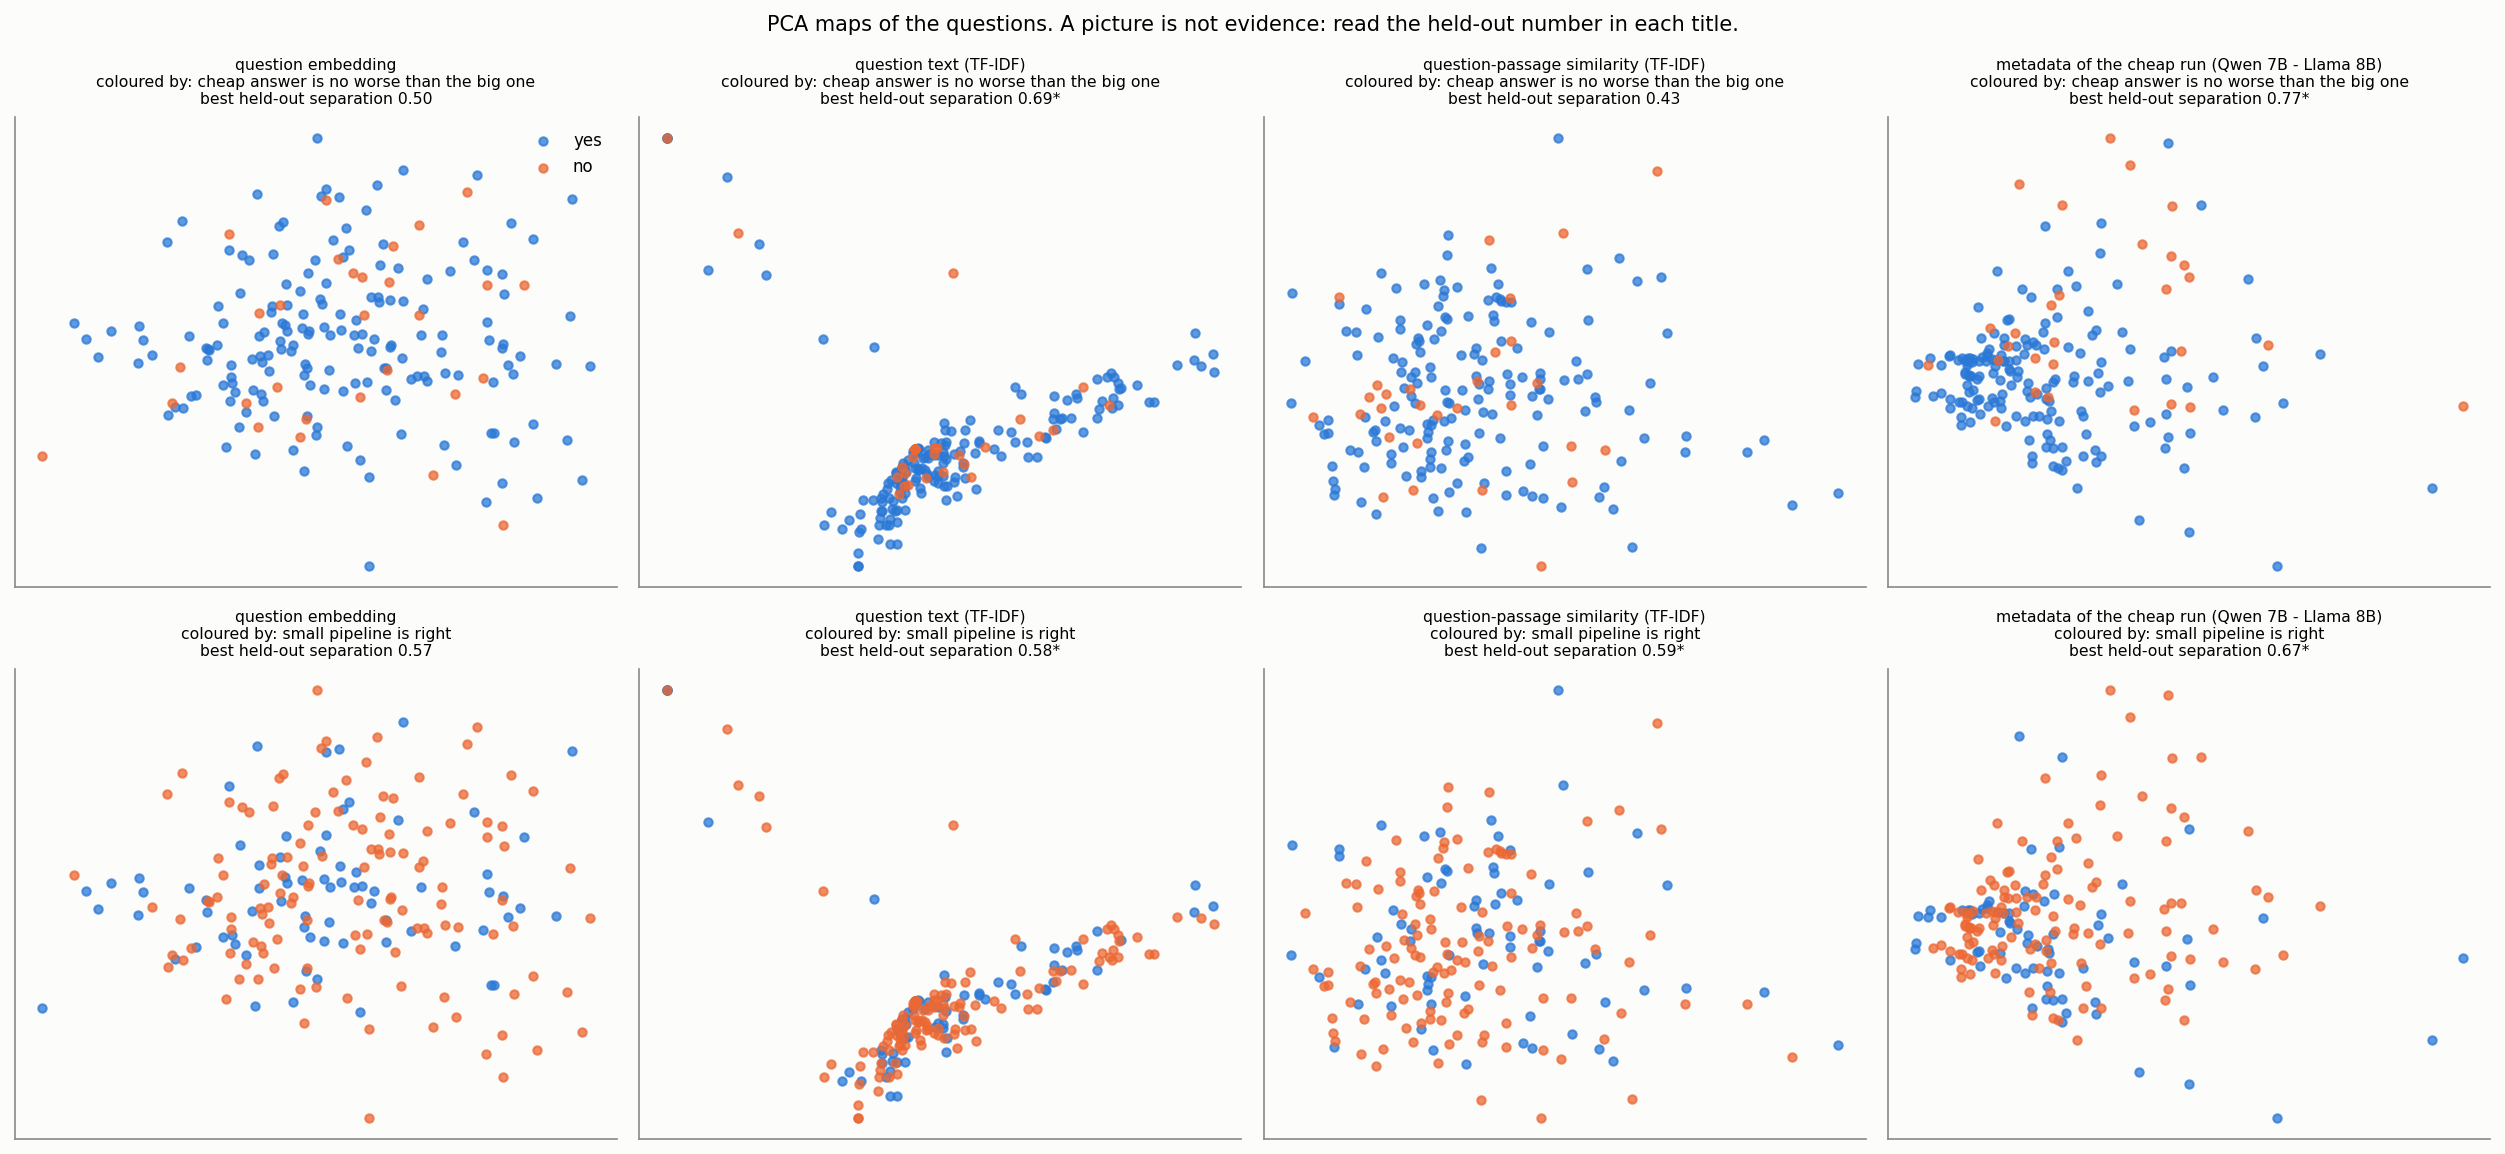

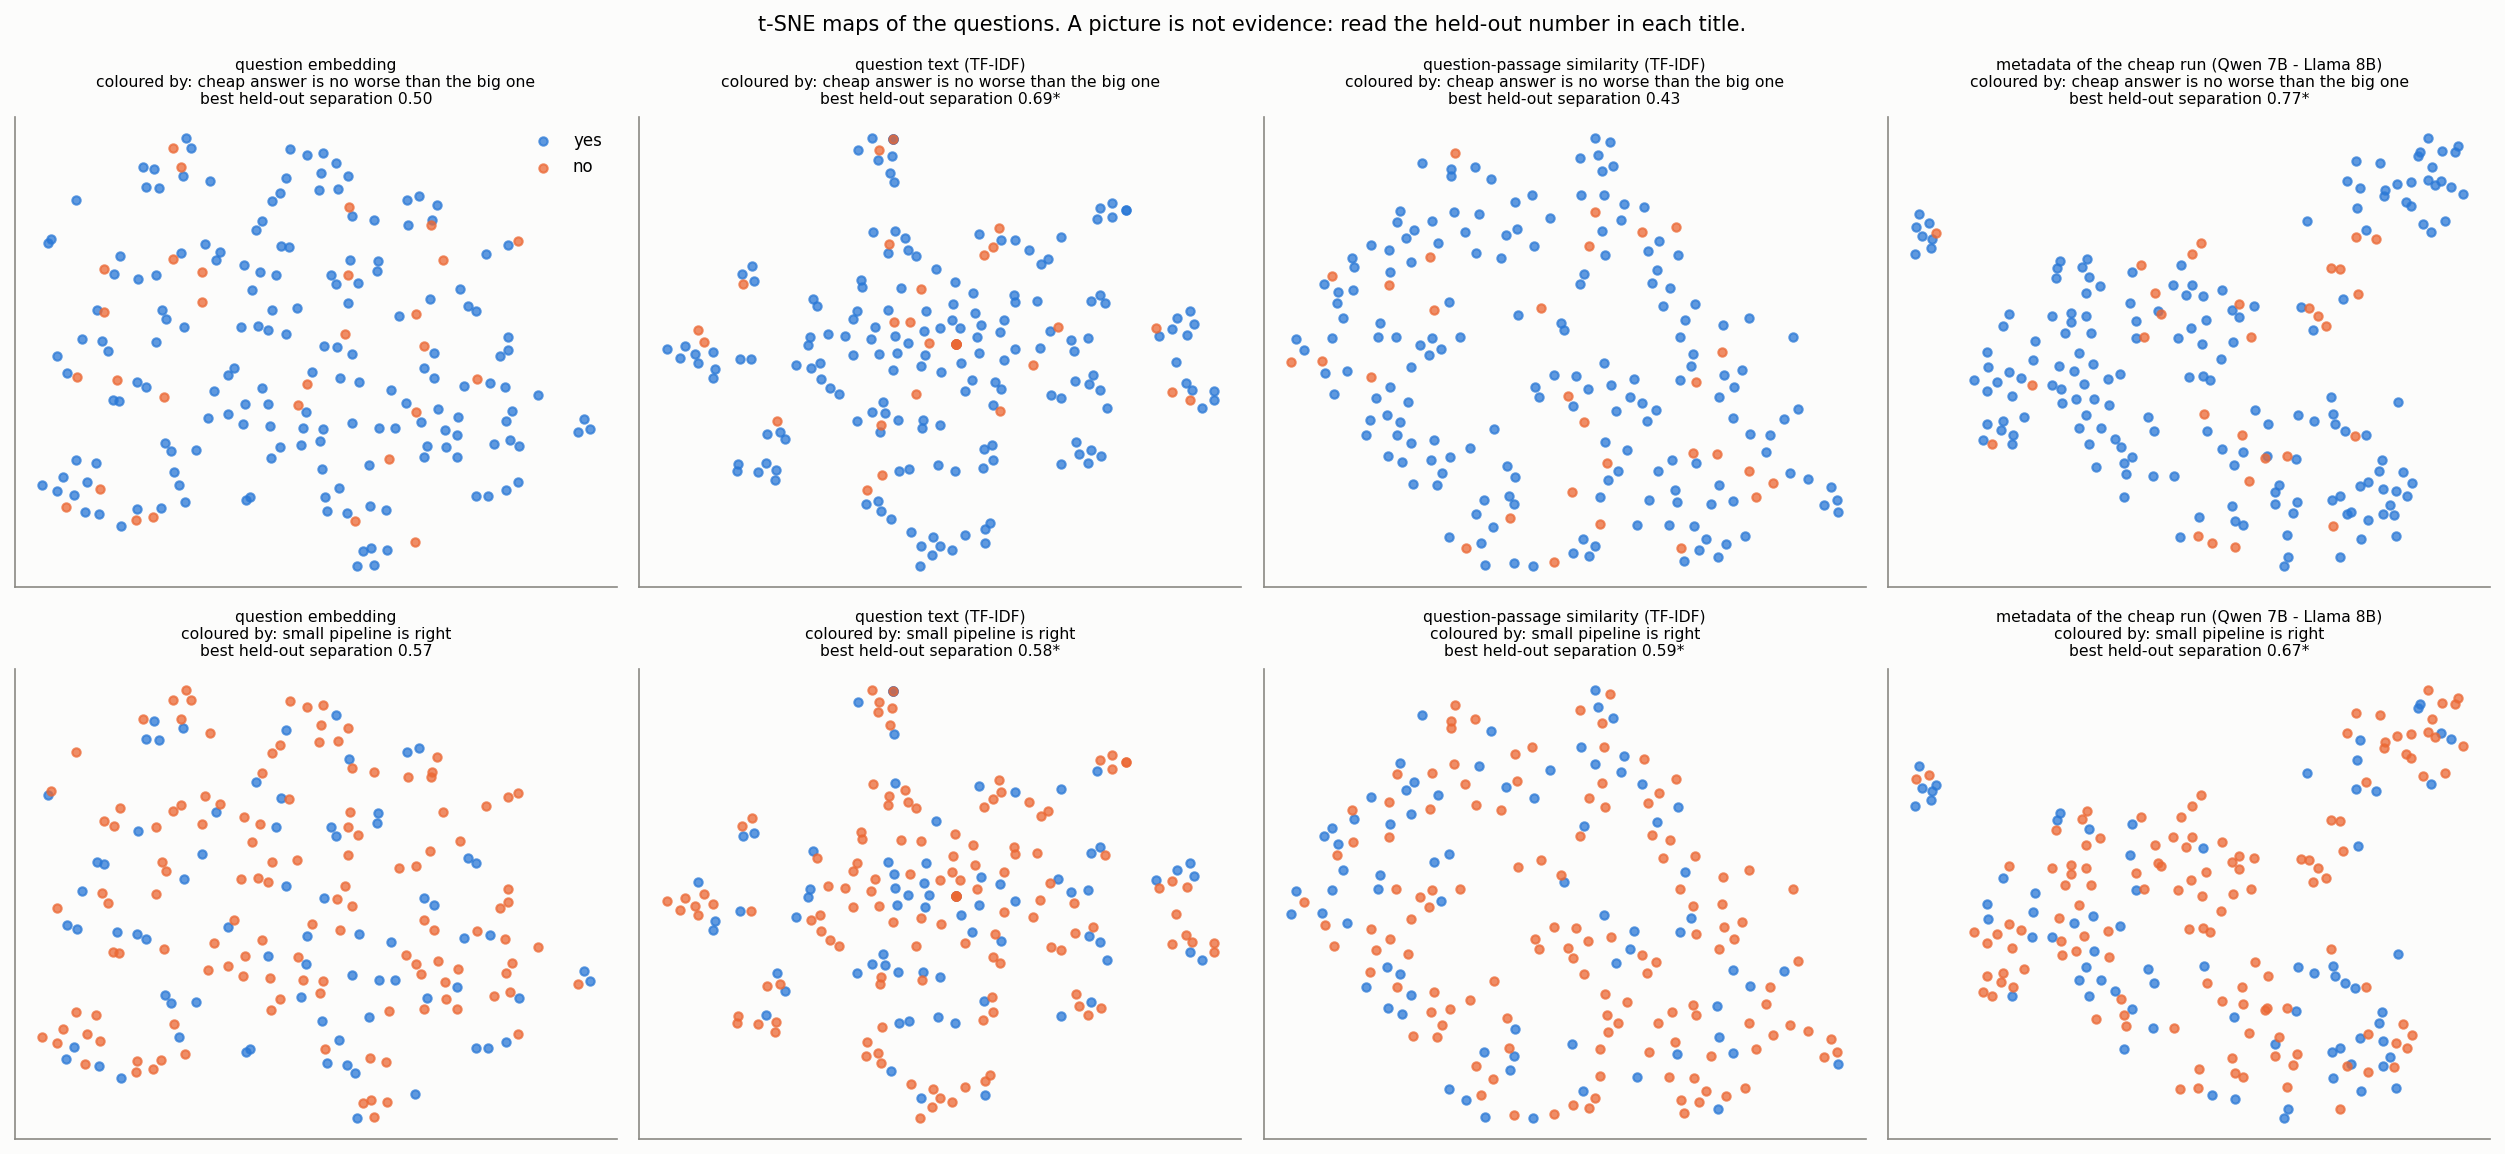

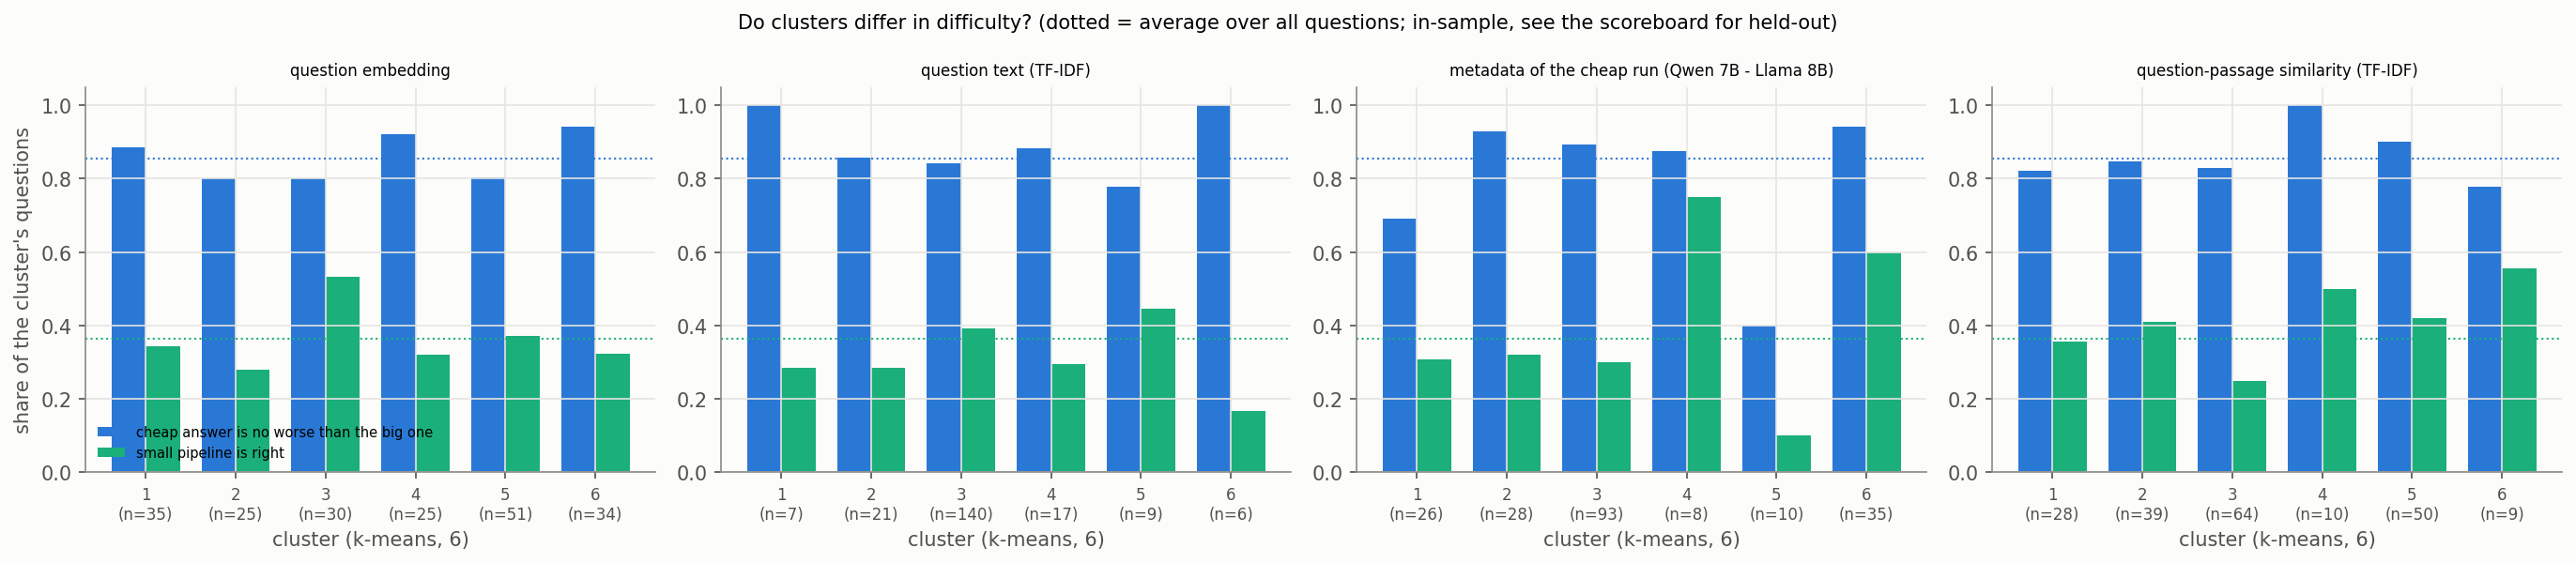

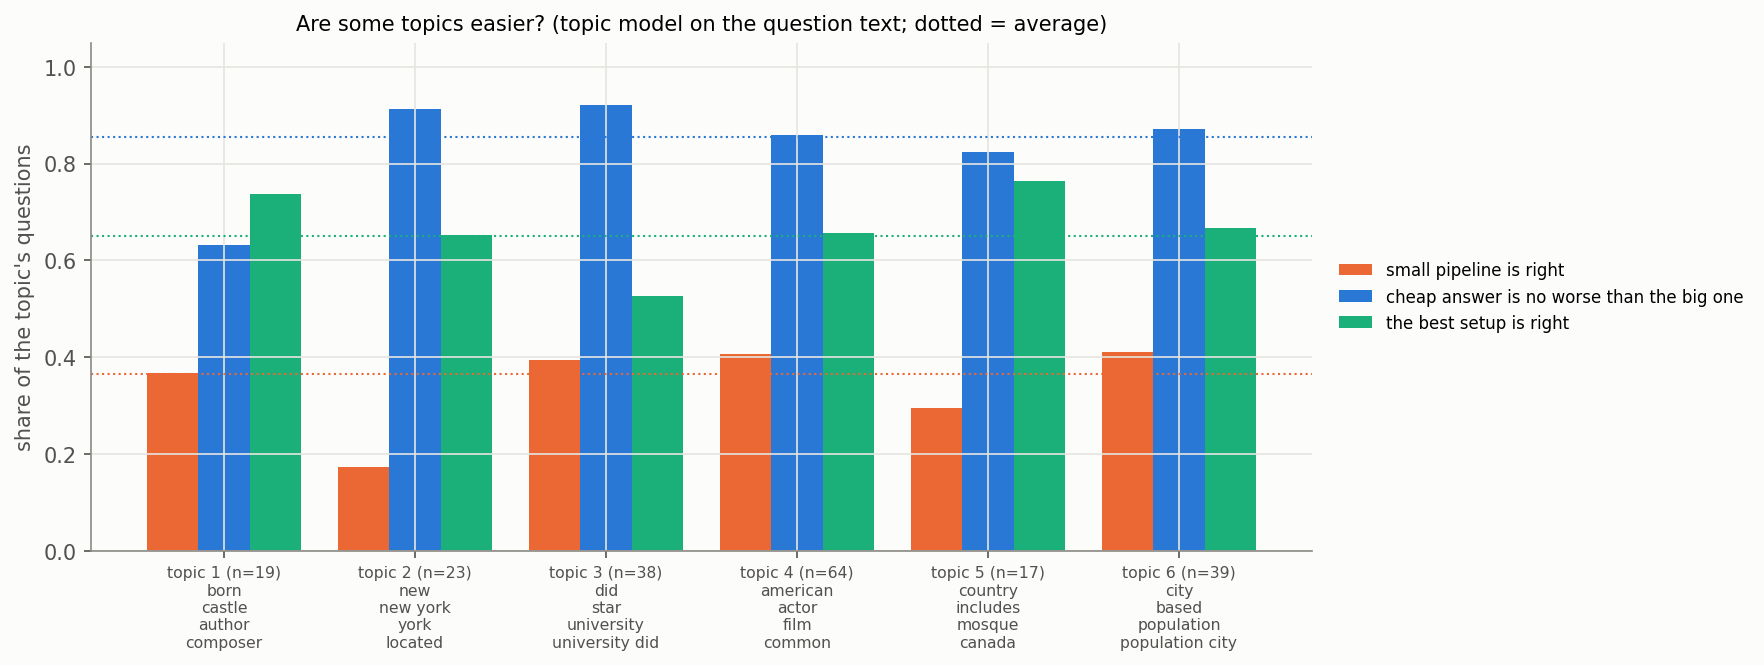

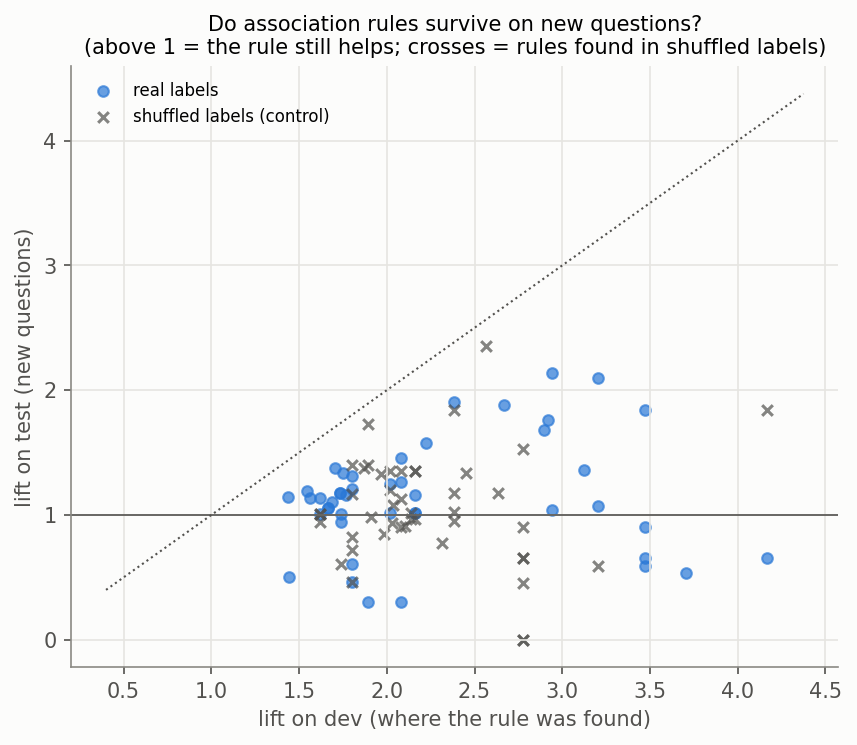

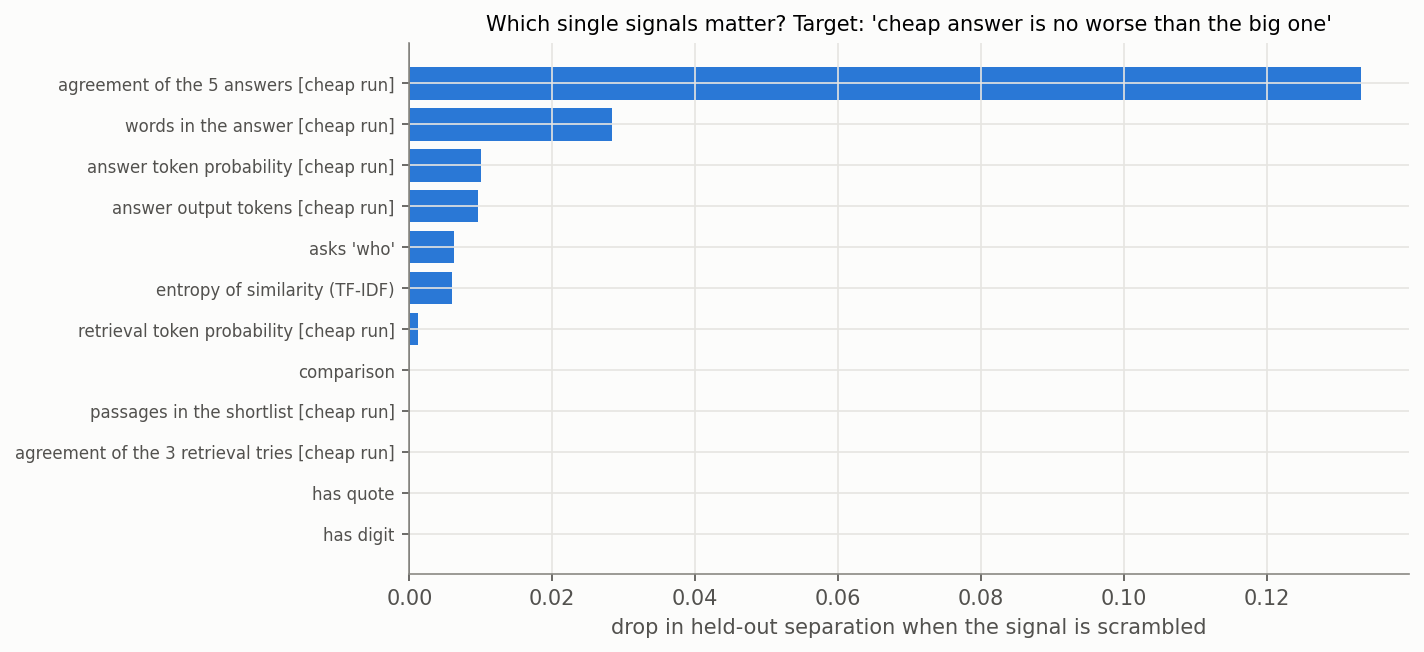

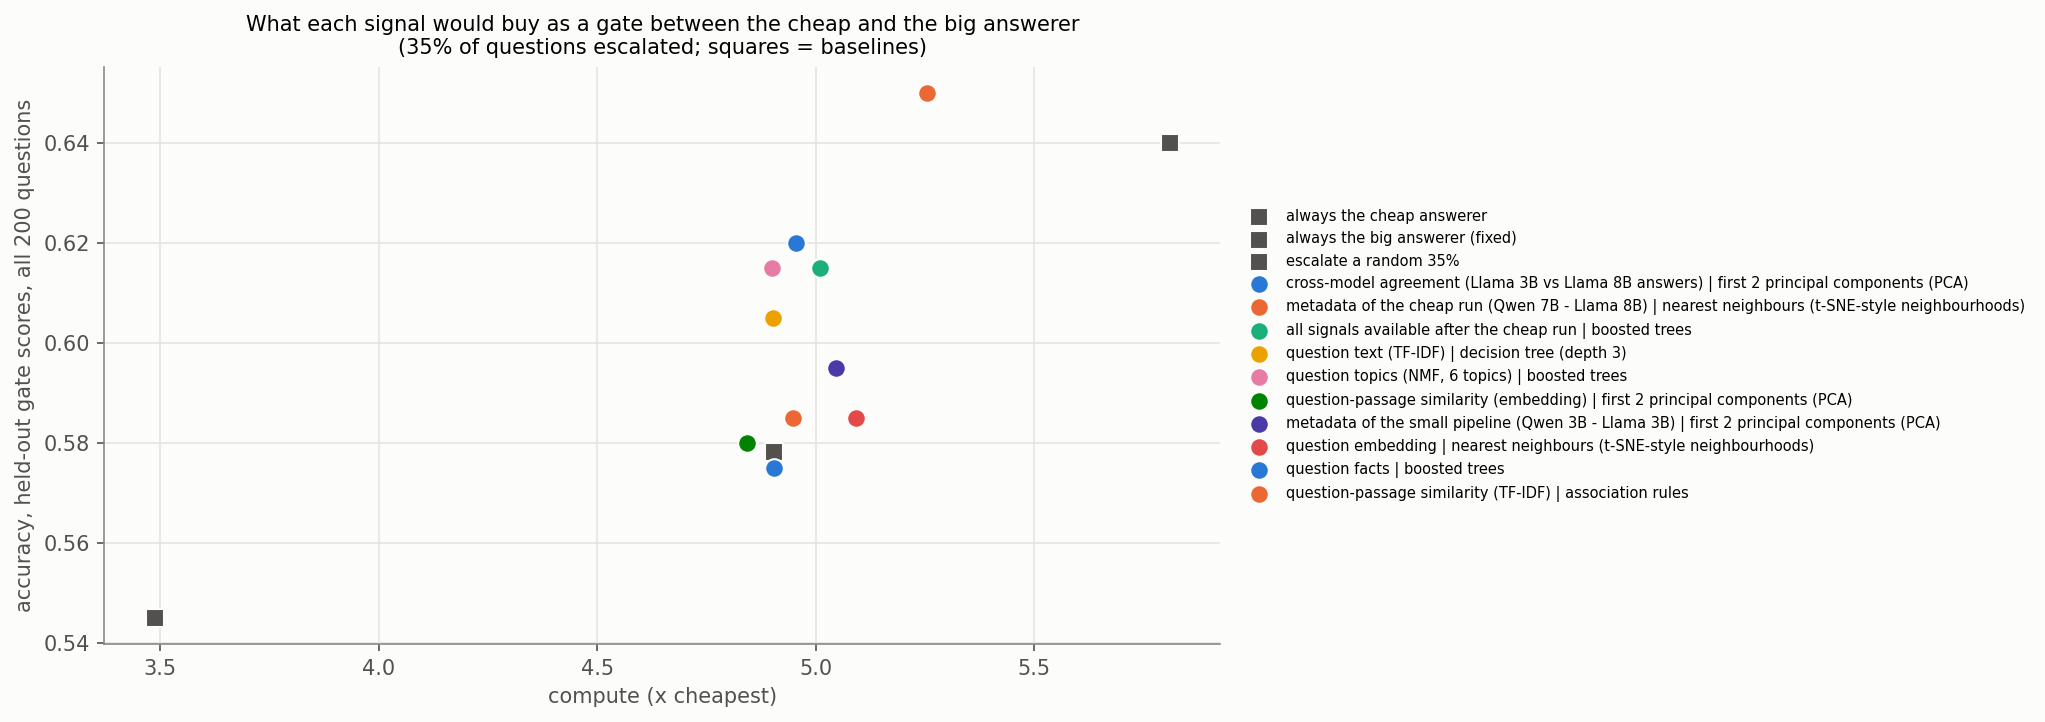

Excel workbook: /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/Set_2__question-reading-routers/20261006-181713_cpu_structure/results/set5d_structure.xlsx
Readable tree rules: /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/Set_2__question-reading-routers/20261006-181713_cpu_structure/results/tree_rules.txt
Wall-clock this session (s): {'total_session': 1086}
Saved to Drive.


In [6]:
from IPython.display import Image, Markdown, display
display(Markdown(open(f"{RUN_DIR}/results/summary.md").read()))
for f in sorted(glob.glob(f"{RUN_DIR}/results/charts/*.png")):
    display(Image(f))
os.makedirs(f"{SESSION_DIR}/results_snapshot", exist_ok=True)
for f in ("summary.md", "set5d_structure.xlsx", "scoreboard.jsonl", "tree_rules.txt"):
    shutil.copy(f"{RUN_DIR}/results/{f}", f"{SESSION_DIR}/results_snapshot/{f}")
shutil.copytree(f"{RUN_DIR}/results/charts", f"{SESSION_DIR}/results_snapshot/charts", dirs_exist_ok=True)
TIMES = {"total_session": round(time.time() - T_START)}
json.dump({"session": SESSION, "label": "structure", "sweep_run": SWEEP_RUN, "run_dir": RUN_DIR, "seconds": TIMES,
           "status": json.load(open(f"{RUN_DIR}/structure_status.json"))}, open(f"{SESSION_DIR}/session.json", "w"), indent=1)
print("Excel workbook:", f"{RUN_DIR}/results/set5d_structure.xlsx")
print("Readable tree rules:", f"{RUN_DIR}/results/tree_rules.txt")
print("Wall-clock this session (s):", TIMES)
try:
    drive.flush_and_unmount()          # make sure everything reaches Drive
    print("Saved to Drive.")
except Exception as e:
    print("Drive flush skipped:", e)